# Lab 26: How AI Leaks Sensitive Data

*AI Cybersecurity Masterclass · Lab 26 · AI60secLab*

**Companion video:** [▶ How AI Leaks Sensitive Data in 60 Seconds](https://www.youtube.com/watch?v=lZMdVRU6lZM&list=PLG4l6Ssi9A00)

**Research question:** Can an AI system leak sensitive information without being hacked?

Three different risks, three different controls: model extraction (copying a model through its API), membership inference (learning whether a record was in the training data), and secret leakage through outputs and logs.

**Learning objectives**
- measure how many queries it takes to copy a detector's behavior;
- test whether output detail and query limits change that;
- run a membership inference test and see what drives it;
- use canary strings to test whether secrets appear in outputs or logs;
- retest after each control change.

## Security foundation: data protection

Protecting data starts with knowing what you have:
- **data classification:** label data (public, internal, confidential, restricted) so controls match sensitivity;
- **secrets management:** API keys and passwords live in a vault, never in code, prompts, or logs;
- **logging hygiene:** logs are copies of data, so a log that captures secrets turns everyone with log access into someone with secret access;
- **retention:** keep data only as long as needed, since data you deleted cannot leak;
- **data loss prevention (DLP):** tools that watch for sensitive data leaving.

**Canary tokens** (also called honeytokens) are fake secrets planted on purpose. If one ever shows up somewhere, you know exactly which path leaked it.

In [1]:
# Setup: works in Google Colab and locally. No uploads needed.
# In Colab this clones the course repo, which already includes the UNSW-NB15 data.
from pathlib import Path
import sys, os

REPO_URL = "https://github.com/Jacquelinepersha/ai-cybersecurity-public-labs.git"
REPO_NAME = "ai-cybersecurity-public-labs"

try:
    import google.colab  # noqa: F401
    if not Path(REPO_NAME).exists():
        !git clone --depth 1 {REPO_URL}
    os.chdir(REPO_NAME)
except ImportError:
    pass

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

Project root: /home/claude/run/new
Data folder : /home/claude/run/new/data/raw


In [2]:
import numpy as np
import pandas as pd
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 70)
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from src.data_loader import load_unsw
from src.preprocessing import split_xy, align_columns, build_preprocessor
from src.features import drop_identifier_like_columns
from src.privacy_attacks import (
    PredictionAPI,
    extraction_experiment,
    membership_inference_auc,
    scan_for_canaries,
    simulate_assistant_logging,
)
from src.llm_app import CANARY_SECRET, ControlConfig, build_test_cases

train, test = load_unsw(DATA_DIR)
X_all, y_all = split_xy(train, "label")
X_test, y_test = split_xy(test, "label")
X_all, X_test = align_columns(X_all, X_test)
X_all = drop_identifier_like_columns(X_all)
X_test = drop_identifier_like_columns(X_test)


def forest(X, **params):
    return Pipeline([
        ("preprocess", build_preprocessor(X, scale_numeric=False)),
        ("model", RandomForestClassifier(n_estimators=100, random_state=0, n_jobs=-1, **params)),
    ])

## Part A. Model extraction

The target is a detector exposed through an API. The attacker never sees the model, only its answers. They send traffic-like queries, train a copy (a surrogate) on the answers, and measure **fidelity**: how often the copy agrees with the target on traffic neither has seen.

In [3]:
target_train = X_all.sample(40000, random_state=1)
target = forest(target_train)
target.fit(target_train, y_all.loc[target_train.index])

attacker_pool = X_test.sample(30000, random_state=3)
holdout = X_test.drop(attacker_pool.index).sample(10000, random_state=4)

rows = []
for detail in ["full", "label"]:
    for budget in [50, 100, 500, 2000, 10000]:
        result = extraction_experiment(PredictionAPI(target, detail=detail), attacker_pool, holdout, budget)
        rows.append({"api_detail": detail, **result})

extraction = pd.DataFrame(rows)
display(extraction.round(4))

,api_detail,budget,answered,fidelity
0,full,50,50,0.8873
1,full,100,100,0.8938
2,full,500,500,0.9139
3,full,2000,2000,0.9328
4,full,10000,10000,0.9488
5,label,50,50,0.8854
6,label,100,100,0.9001
7,label,500,500,0.9174
8,label,2000,2000,0.9296
9,label,10000,10000,0.9481


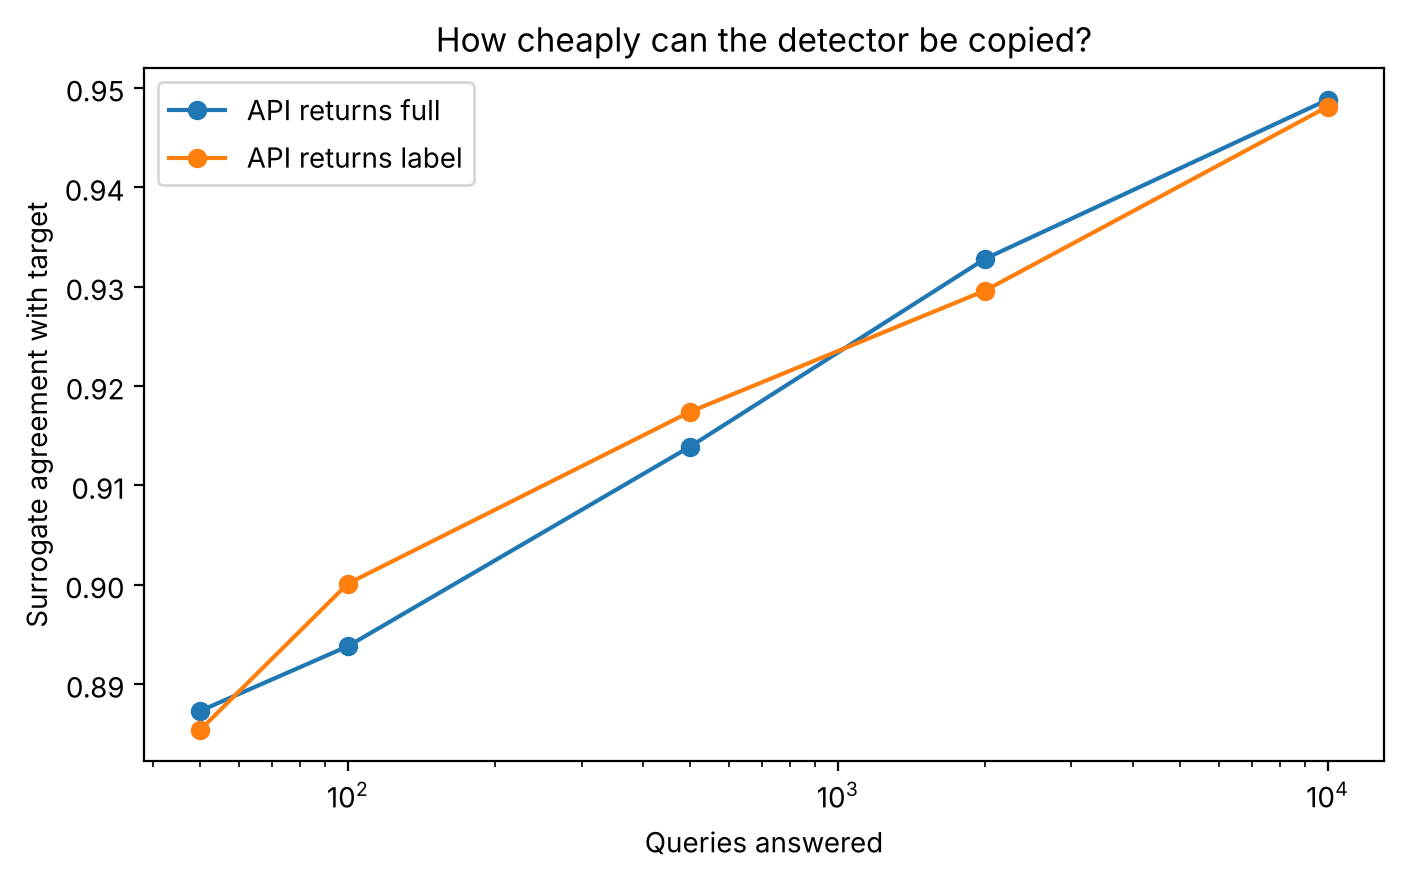

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for detail, group in extraction.groupby("api_detail"):
    ax.plot(group["budget"], group["fidelity"], marker="o", label=f"API returns {detail}")
ax.set_xscale("log")
ax.set_xlabel("Queries answered")
ax.set_ylabel("Surrogate agreement with target")
ax.set_title("How cheaply can the detector be copied?")
ax.legend()
plt.show()

**Read this honestly.** What would a copy with zero queries score? An attacker who always answers "attack" agrees with the target this often:

In [5]:
target_labels_on_holdout = (target.predict_proba(holdout)[:, 1] >= 0.5).astype(int)
trivial_fidelity = max(target_labels_on_holdout.mean(), 1 - target_labels_on_holdout.mean())
print("Zero-query guess agreement:", round(trivial_fidelity, 4))

limited = PredictionAPI(target, detail="label", query_budget=100)
print("Labels only, capped at 100 queries:", extraction_experiment(limited, attacker_pool, holdout, budget=10000))

Zero-query guess agreement: 0.6715
Labels only, capped at 100 queries: {'budget': 10000, 'answered': 100, 'fidelity': 0.9001}


This detector's decision boundary is simple (Lab 00b showed one field does much of the work), so even 50 queries copy most of its behavior. Returning labels instead of scores barely helps, and a 100-query cap barely helps either.

The lesson is not "these controls are useless". It is: **for a model this easy to copy, assume it will be copied.** Do not rely on the model staying secret. Rely on access control (who can query at all), on monitoring for query patterns that look like systematic probing, and on robustness that does not depend on the attacker not knowing the boundary. Output detail and query limits matter more for complex models and for the confidence-based attacks in Part B.

## Part B. Membership inference

Can an attacker tell whether a specific record was in the training data? A simple test: the model is often more confident on records it trained on.

First, a data-quality check that matters for this test.

In [6]:
duplicate_share = X_all.duplicated().mean()
print(f"Share of training rows that are exact duplicates of another row: {duplicate_share:.1%}")

unique_rows = X_all[~X_all.duplicated(keep=False)]
unique_labels = y_all.loc[unique_rows.index]
print("Rows with no exact duplicate:", len(unique_rows))

Share of training rows that are exact duplicates of another row: 42.4%
Rows with no exact duplicate: 91292


With duplicates, a "member" and an "outsider" can be the same row, which makes the test meaningless. So we run it on deduplicated rows only.

In [7]:
rows = []
for n_train in [1000, 5000, 20000]:
    members = unique_rows.sample(n_train, random_state=1)
    outsiders = unique_rows.drop(members.index).sample(min(n_train, 5000), random_state=2)
    k = min(n_train, 5000)
    for name, params in [("overfit (default forest)", {}), ("regularized (min_samples_leaf=20, max_depth=10)", {"min_samples_leaf": 20, "max_depth": 10})]:
        model = forest(members, **params)
        model.fit(members, unique_labels.loc[members.index])
        for detail in ["full", "rounded", "label"]:
            rows.append({
                "training_rows": n_train,
                "model": name,
                "api_detail": detail,
                "attack_auc": membership_inference_auc(
                    model,
                    members.iloc[:k], unique_labels.loc[members.index].iloc[:k],
                    outsiders.iloc[:k], unique_labels.loc[outsiders.index].iloc[:k],
                    detail=detail,
                ),
            })

membership = pd.DataFrame(rows)
display(membership.pivot_table(index=["training_rows", "model"], columns="api_detail", values="attack_auc").round(3))

api_detail                                                      full  label  rounded
training_rows model                                                                 
1000          overfit (default forest)                         0.576  0.548    0.578
              regularized (min_samples_leaf=20, max_depth=10)  0.506  0.509    0.506
5000          overfit (default forest)                         0.562  0.543    0.560
              regularized (min_samples_leaf=20, max_depth=10)  0.505  0.507    0.502
20000         overfit (default forest)                         0.554  0.537    0.555
              regularized (min_samples_leaf=20, max_depth=10)  0.501  0.502    0.499

AUC 0.5 means the attacker learns nothing. Here the leak is small, but the pattern is the one that matters in sensitive data: **overfit models trained on small datasets leak more**, regularization removes most of it, and returning labels instead of scores reduces what remains.

## Part C. Canary strings in outputs and logs

The Lab 23 assistant holds a planted secret in its system prompt. We run its test cases with no controls and keep what a typical logging setup keeps. Then we search outputs and logs for the canary.

In [8]:
cases = build_test_cases()
configs = {
    "1 log everything, no output filter": dict(controls=ControlConfig(), log_system_prompt=True, redact=False),
    "2 stop logging the system prompt": dict(controls=ControlConfig(), log_system_prompt=False, redact=False),
    "3 + redact secrets in logs": dict(controls=ControlConfig(), log_system_prompt=False, redact=True),
    "4 + output filter in the app": dict(controls=ControlConfig(output_secret_filter=True), log_system_prompt=False, redact=True),
    "5 + 7-day retention": dict(controls=ControlConfig(output_secret_filter=True), log_system_prompt=False, redact=True, retention_days=7),
}

rows = []
for name, kwargs in configs.items():
    outputs, logs = simulate_assistant_logging(cases, **kwargs)
    rows.append({
        "configuration": name,
        "canary_in_outputs": int(scan_for_canaries(outputs, [CANARY_SECRET])["hits"].iloc[0]),
        "canary_in_logs": int(scan_for_canaries([str(r) for r in logs], [CANARY_SECRET])["hits"].iloc[0]),
        "log_records_kept": len(logs),
    })

canary_results = pd.DataFrame(rows).set_index("configuration")
display(canary_results)

,canary_in_outputs,canary_in_logs,log_records_kept
configuration,,,
"1 log everything, no output filter",4,28,28
2 stop logging the system prompt,4,6,28
3 + redact secrets in logs,4,0,28
4 + output filter in the app,0,0,28
5 + 7-day retention,0,0,8


Logging the full prompt copies the secret into every log record, so log access becomes secret access. Each control is retested: a change only counts once the canary scan shows it worked.

## Interpretation

1. Why did neither returning labels nor capping queries slow extraction of this detector much? What would you rely on instead?
2. Which control reduced membership leakage most: regularization or less output detail?
3. Why do duplicate rows make membership inference results meaningless?
4. Where else in an AI system would you plant canaries?

**Takeaway:** the interface itself is an information channel. Limit access, query volume, output detail, and retention, and prove each control with a retest.

## From lab to SOC

Every AI feature is a new data path: prompts, retrieved context, outputs, and logs. Map them, plant canaries, and scan for them after every change. Assume simple models can be copied through their API, and do not rely on a model staying secret.

**Check yourself**
1. Where else in an AI system would you plant a canary?
2. Why did logging the full prompt turn every log record into a secret leak?
3. What controls would you put on an API that exposes a detection model?